# PMSM Dataset — Exploration

In this notebook I explore the **Electric Motor Temperature (PMSM)** dataset and look at its
structure, variables, and the relationships between them. The aim is to understand the data
properly before using it for the neural-network pruning experiments later in the case study.

The notes assume no background in motor engineering — I didn't have much either when I started,
so I worked out what each variable means as I went.

**Dataset:** [Kaggle — wkirgsn/electric-motor-temperature](https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature)
(`measures_v2.csv`, ~138 MB). Place the file in a `data/` folder next to this notebook.

## Setup

In [1]:
import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Feature groups
INPUT_FEATURES  = ["u_q", "u_d", "i_q", "i_d", "motor_speed", "torque", "ambient", "coolant"]
TARGET_FEATURES = ["pm", "stator_winding", "stator_tooth", "stator_yoke"]

# Variables ordered by physical category (used for the correlation heatmap)
ORDERED_VARS = [
    "u_q", "u_d", "i_q", "i_d",          # Electrical
    "motor_speed", "torque",             # Mechanical
    "ambient", "coolant",                # Environmental
    "pm", "stator_winding", "stator_tooth", "stator_yoke",  # Targets
]

# Colors by category
C_ELEC = "#2e75b6"   # electrical
C_MECH = "#1f4e79"   # mechanical
C_ENV  = "#0070c0"   # environmental
C_TEMP = "#c00000"   # temperature outputs

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
})

# One consistent color per variable, reused across every figure so the
# same variable always looks the same wherever it appears.
VAR_COLORS = {
    "motor_speed": "#1f4e79", "torque": "#e36c09",
    "u_q": "#2e75b6", "u_d": "#c00000", "i_q": "#375623", "i_d": "#7030a0",
    "ambient": "#0070c0", "coolant": "#00b0f0",
    "pm": "#c00000", "stator_winding": "#e36c09",
    "stator_tooth": "#0070c0", "stator_yoke": "#7030a0",
}

## 1. Load the data

First I load the CSV and check the basics: how big it is, whether anything is missing, and
how many separate recording sessions (`profile_id`) there are.

In [2]:
df = pd.read_csv("data/measures_v2.csv")

n_samples  = len(df)
n_profiles = df["profile_id"].nunique()

print(f"Rows           : {n_samples:,}")
print(f"Columns        : {df.shape[1]}")
print(f"Profiles       : {n_profiles}")
print(f"Missing values : {df.isnull().sum().sum()}")
df.head()

Rows           : 1,330,816
Columns        : 13
Profiles       : 69
Missing values : 0


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


## What is a PMSM, and what are we predicting?

A **PMSM** (Permanent Magnet Synchronous Motor) is an electric motor with permanent magnets on
its rotating part. Current in the surrounding coils creates a rotating magnetic field that pulls
the magnets around. These motors are common in electric vehicles and drones.

When the motor runs it heats up, and if it gets too hot the magnets can be permanently damaged.
Measuring the internal temperatures directly is hard in a real vehicle, so the goal is to
**predict them from signals that are easy to measure**.

- **Inputs (easy to measure):**
  - Electrical — `u_q`, `u_d`, `i_q`, `i_d`
  - Mechanical — `motor_speed`, `torque`
  - Environmental — `ambient`, `coolant`
- **Outputs (hard to measure, what we predict):** `pm`, `stator_winding`, `stator_tooth`, `stator_yoke`
- **Metadata:** `profile_id` — which recording session each row belongs to.

This is a **multi-output regression** problem: predict four continuous temperatures at once
from the eight inputs.

## 2. What each variable means

In [3]:
var_table = pd.DataFrame([
    ("u_q",            "q-axis voltage",            "Voltage driving the torque-producing direction", "Electrical",    "Input"),
    ("u_d",            "d-axis voltage",            "Voltage in the magnetic-field direction",        "Electrical",    "Input"),
    ("i_q",            "q-axis current",            "Current that produces the rotating torque",      "Electrical",    "Input"),
    ("i_d",            "d-axis current",            "Current that controls the magnetic field",       "Electrical",    "Input"),
    ("motor_speed",    "Rotational speed",          "How fast the shaft spins (RPM)",                 "Mechanical",    "Input"),
    ("torque",         "Motor torque",              "The turning force produced (Nm)",                "Mechanical",    "Input"),
    ("ambient",        "Ambient temperature",       "Temperature of the surrounding air",             "Environmental", "Input"),
    ("coolant",        "Coolant temperature",       "Temperature of the cooling liquid",              "Environmental", "Input"),
    ("pm",             "Permanent magnet temp.",    "Temperature of the rotor magnets",               "Thermal",       "Output"),
    ("stator_winding", "Stator winding temp.",      "Temperature of the copper coils",                "Thermal",       "Output"),
    ("stator_tooth",   "Stator tooth temp.",        "Temperature of the iron teeth holding the coils","Thermal",       "Output"),
    ("stator_yoke",    "Stator yoke temp.",         "Temperature of the outer iron ring",             "Thermal",       "Output"),
    ("profile_id",     "Operating session ID",      "Marks which recording session a row is from",    "Metadata",      "Grouping"),
], columns=["Variable", "Full name", "Meaning", "Category", "Role"])

var_table

,Variable,Full name,Meaning,Category,Role
0,u_q,q-axis voltage,Voltage driving the torque-producing direction,Electrical,Input
1,u_d,d-axis voltage,Voltage in the magnetic-field direction,Electrical,Input
2,i_q,q-axis current,Current that produces the rotating torque,Electrical,Input
3,i_d,d-axis current,Current that controls the magnetic field,Electrical,Input
4,motor_speed,Rotational speed,How fast the shaft spins (RPM),Mechanical,Input
5,torque,Motor torque,The turning force produced (Nm),Mechanical,Input
6,ambient,Ambient temperature,Temperature of the surrounding air,Environmental,Input
7,coolant,Coolant temperature,Temperature of the cooling liquid,Environmental,Input
8,pm,Permanent magnet temp.,Temperature of the rotor magnets,Thermal,Output
9,stator_winding,Stator winding temp.,Temperature of the copper coils,Thermal,Output


## 3. Understanding `profile_id`

The data wasn't recorded in one long run — it came from **69 separate test sessions**, each with
a different driving pattern. Every row is tagged with the session it belongs to, and that tag is
`profile_id`.

A few things worth being clear about:

- It is **not a sensor measurement** — just a label (1, 2, 3, ...). A higher number doesn't mean
  "more" of anything, and it should never be fed into a model as an input.
- It is **useful for splitting the data correctly**. If rows from the same session end up in both
  the training and test sets, the model effectively sees the answers and scores look better than
  they really are. Splitting by whole profiles avoids this.

Below I plot how many samples each session has.

Largest session : ID 20 (43,971 samples)
Smallest session: ID 47 (2,176 samples)


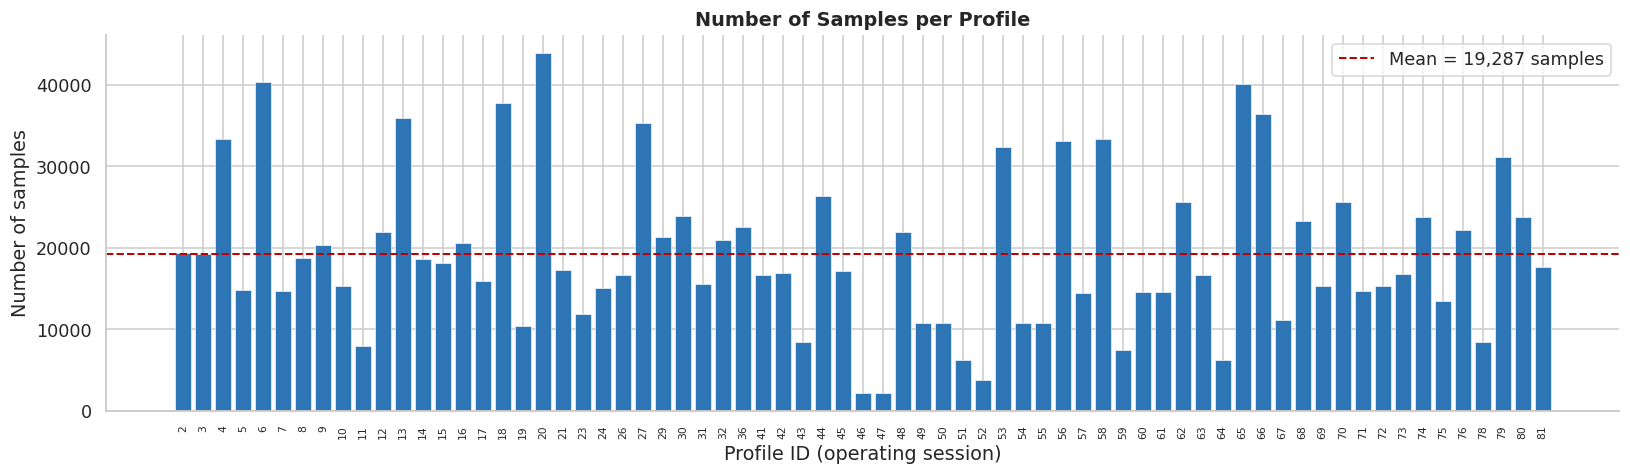

In [4]:
profile_counts = df["profile_id"].value_counts().sort_index()
print(f"Largest session : ID {profile_counts.idxmax()} ({profile_counts.max():,} samples)")
print(f"Smallest session: ID {profile_counts.idxmin()} ({profile_counts.min():,} samples)")

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(profile_counts.index.astype(str), profile_counts.values,
       color=C_ELEC, edgecolor="white", linewidth=0.4)
ax.axhline(profile_counts.mean(), color=C_TEMP, linestyle="--", linewidth=1.3,
           label=f"Mean = {profile_counts.mean():,.0f} samples")
ax.set_xlabel("Profile ID (operating session)")
ax.set_ylabel("Number of samples")
ax.set_title("Number of Samples per Profile", fontweight="bold")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend()
plt.tight_layout(); plt.show()

The sessions vary a lot in length — some are short tests, others long runs. This is another
reason a plain random split would be unfair: a few long sessions would dominate the data.

## 4. The dataset in one picture

This diagram sums up the whole idea: easy-to-measure inputs on the left drive the motor in the
middle, and the four temperatures we want to predict come out on the right.

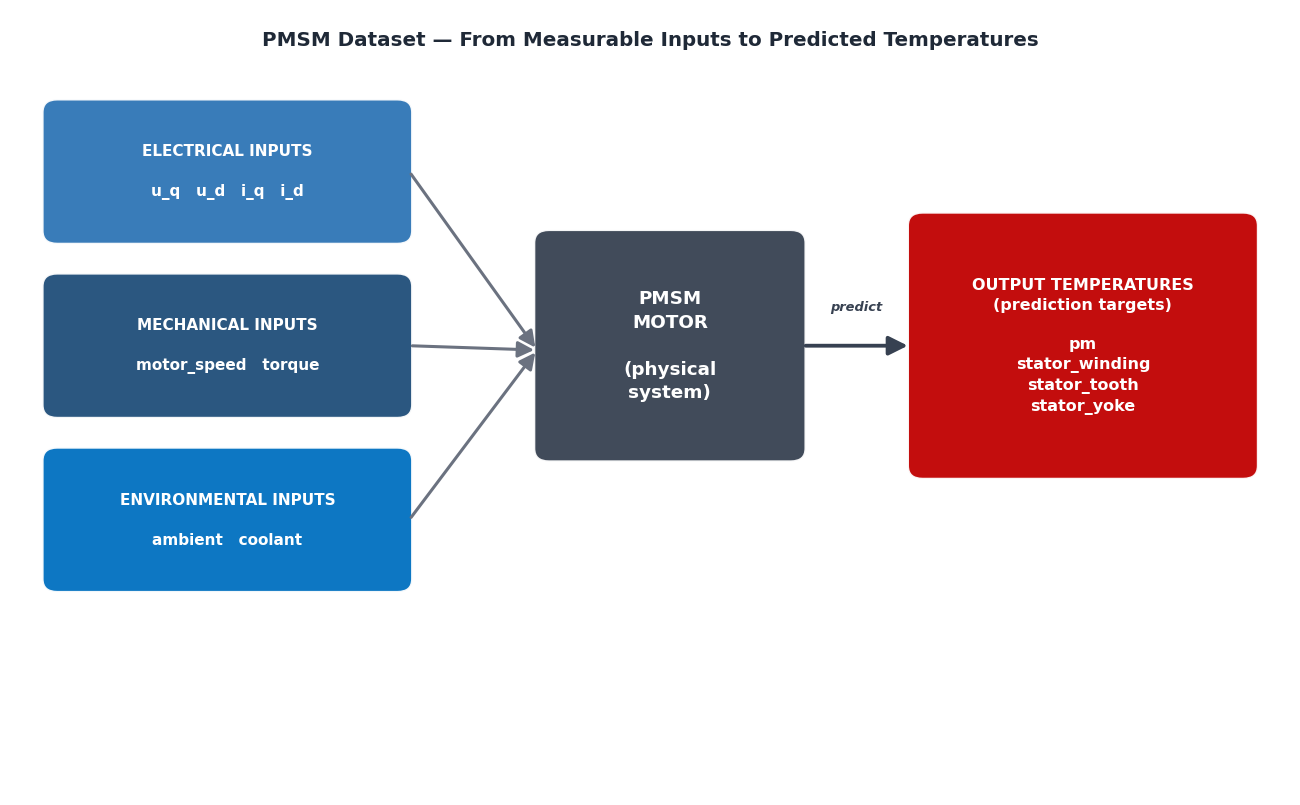

In [5]:
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.set_xlim(0, 13); ax.set_ylim(0, 9); ax.axis("off")

def box(x, y, w, h, text, color, fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08,rounding_size=0.15",
                 linewidth=1.5, edgecolor="white", facecolor=color, alpha=0.95))
    ax.text(x+w/2, y+h/2, text, ha="center", va="center", color="white",
            fontsize=fs, fontweight="bold", linespacing=1.4)

ax.text(6.5, 8.6, "PMSM Dataset — From Measurable Inputs to Predicted Temperatures",
        ha="center", fontsize=13, fontweight="bold", color="#1f2937")

box(0.4, 6.4, 3.6, 1.5, "ELECTRICAL INPUTS\n\nu_q   u_d   i_q   i_d", C_ELEC)
box(0.4, 4.4, 3.6, 1.5, "MECHANICAL INPUTS\n\nmotor_speed   torque", C_MECH)
box(0.4, 2.4, 3.6, 1.5, "ENVIRONMENTAL INPUTS\n\nambient   coolant", C_ENV)
box(5.4, 3.9, 2.6, 2.5, "PMSM\nMOTOR\n\n(physical\nsystem)", "#374151", fs=12)
box(9.2, 3.7, 3.4, 2.9, "OUTPUT TEMPERATURES\n(prediction targets)\n\npm\nstator_winding\nstator_tooth\nstator_yoke", C_TEMP, fs=10.5)

akw = dict(arrowstyle="-|>", mutation_scale=22, linewidth=2, color="#6b7280")
for y in (7.15, 5.15, 3.15):
    ax.add_patch(FancyArrowPatch((4.05, y), (5.35, 5.1), **akw))
ax.add_patch(FancyArrowPatch((8.05, 5.15), (9.15, 5.15),
             arrowstyle="-|>", mutation_scale=26, linewidth=2.5, color="#374151"))
ax.text(8.6, 5.55, "predict", ha="center", fontsize=8.5, color="#374151",
        style="italic", fontweight="bold")
plt.tight_layout(); plt.show()

## 5. Input signals over time

To see how the data behaves over time I pick one representative session — the one whose length is
closest to the median — and plot its input signals. These are the driving conditions the engineers
applied: speed and torque set the demand, and the voltages and currents deliver it.

Representative profile: 45 (17,142 samples)


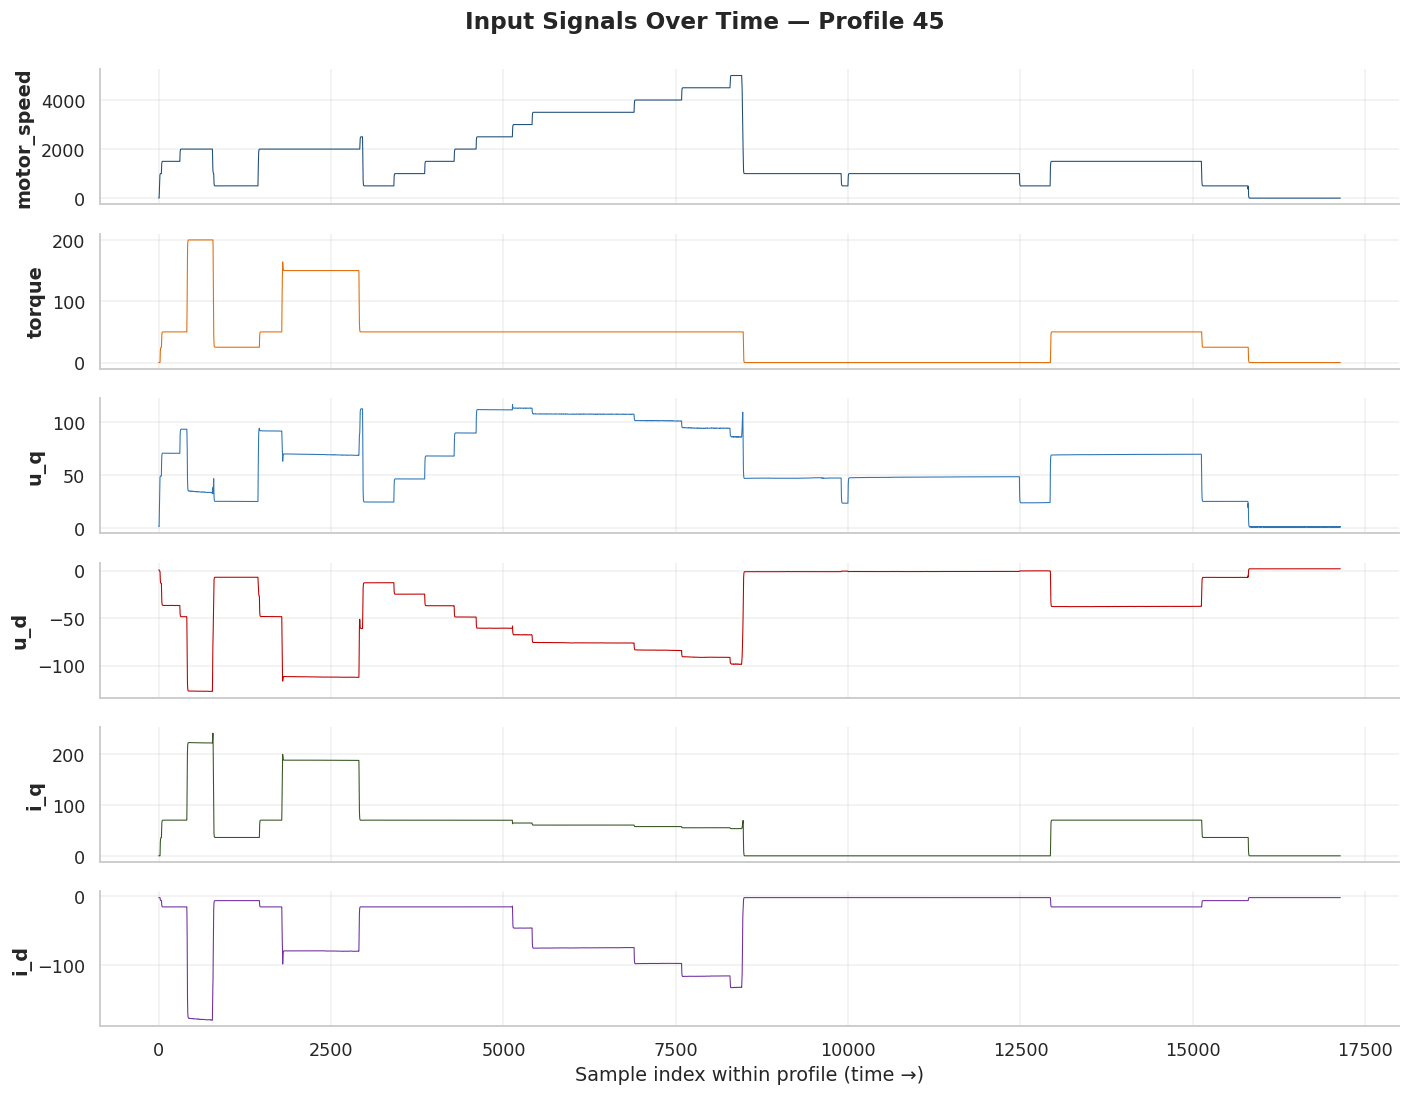

In [6]:
median_len = profile_counts.median()
rep_profile = (profile_counts - median_len).abs().idxmin()
prof = df[df["profile_id"] == rep_profile].reset_index(drop=True)
print(f"Representative profile: {rep_profile} ({len(prof):,} samples)")

input_panels = ["motor_speed", "torque", "u_q", "u_d", "i_q", "i_d"]
fig, axes = plt.subplots(len(input_panels), 1, figsize=(13, 10), sharex=True)
for ax, col in zip(axes, input_panels):
    ax.plot(prof.index, prof[col], color=VAR_COLORS[col], linewidth=0.7)
    ax.set_ylabel(col, fontweight="bold"); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Sample index within profile (time \u2192)")
fig.suptitle(f"Input Signals Over Time — Profile {rep_profile}", fontweight="bold", y=0.995)
plt.tight_layout(); plt.show()

The inputs are jagged and step-like — they change quickly as the operating point changes.

## 6. Output temperatures over time

Now the four temperatures for the same session — these are what the model has to predict.

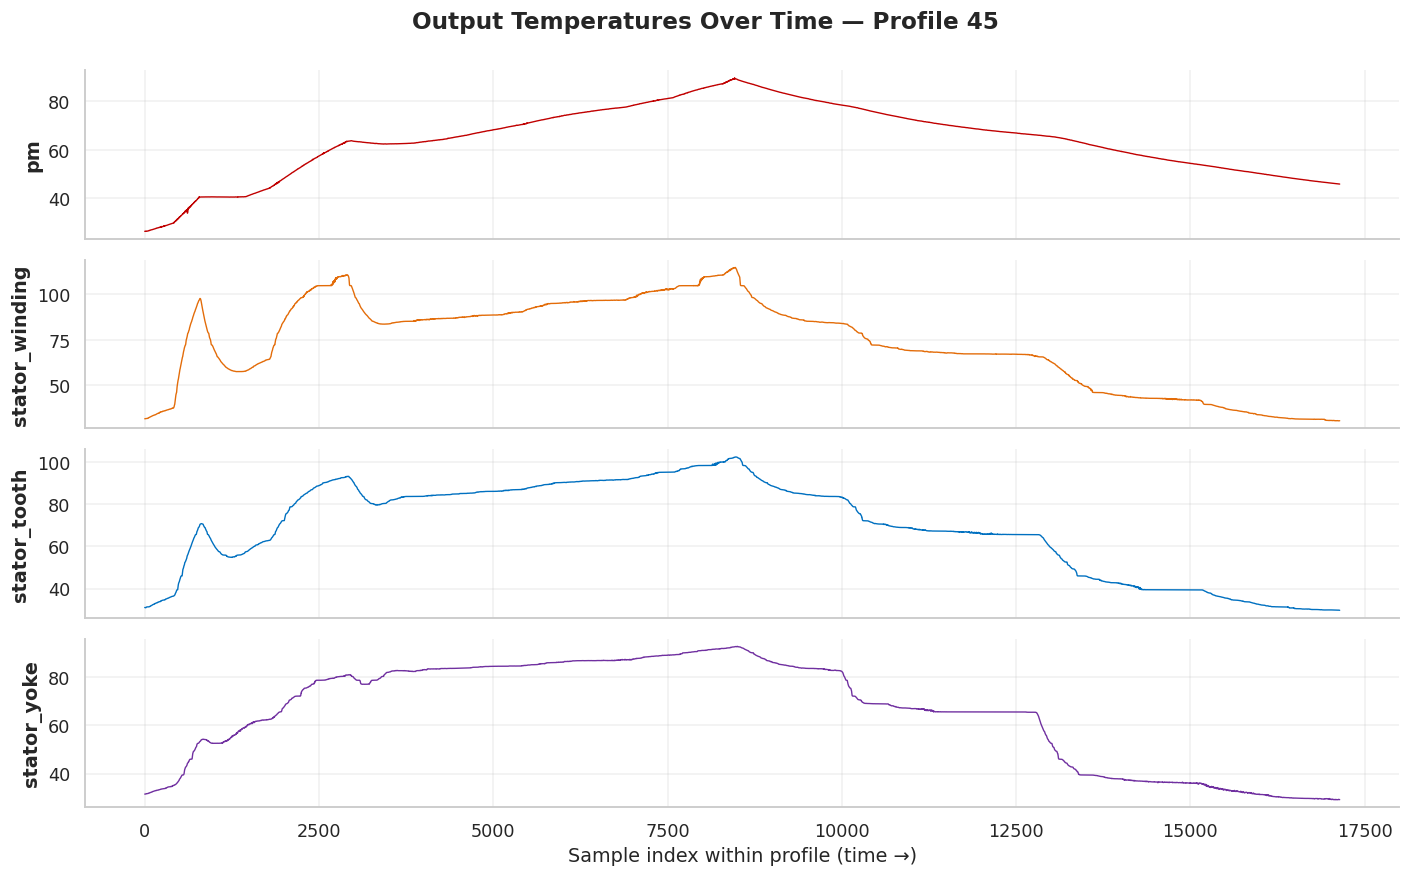

In [7]:
fig, axes = plt.subplots(len(TARGET_FEATURES), 1, figsize=(13, 8), sharex=True)
for ax, col in zip(axes, TARGET_FEATURES):
    ax.plot(prof.index, prof[col], color=VAR_COLORS[col], linewidth=0.9)
    ax.set_ylabel(col, fontweight="bold"); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Sample index within profile (time \u2192)")
fig.suptitle(f"Output Temperatures Over Time — Profile {rep_profile}", fontweight="bold", y=0.995)
plt.tight_layout(); plt.show()

Compared with the inputs, the temperatures are much smoother and change slowly. They respond to
the load in the inputs but with a delay, because the motor parts take time to heat up and cool
down. `pm` (the magnet) also peaks lower and later than the stator parts.

## 7. Inputs and temperatures together (combined view)

Finally, I stack the mechanical inputs, electrical signals, and temperatures for the same session
on one shared time axis. This is the figure I find most useful — reading top to bottom shows the
cause-and-effect directly.

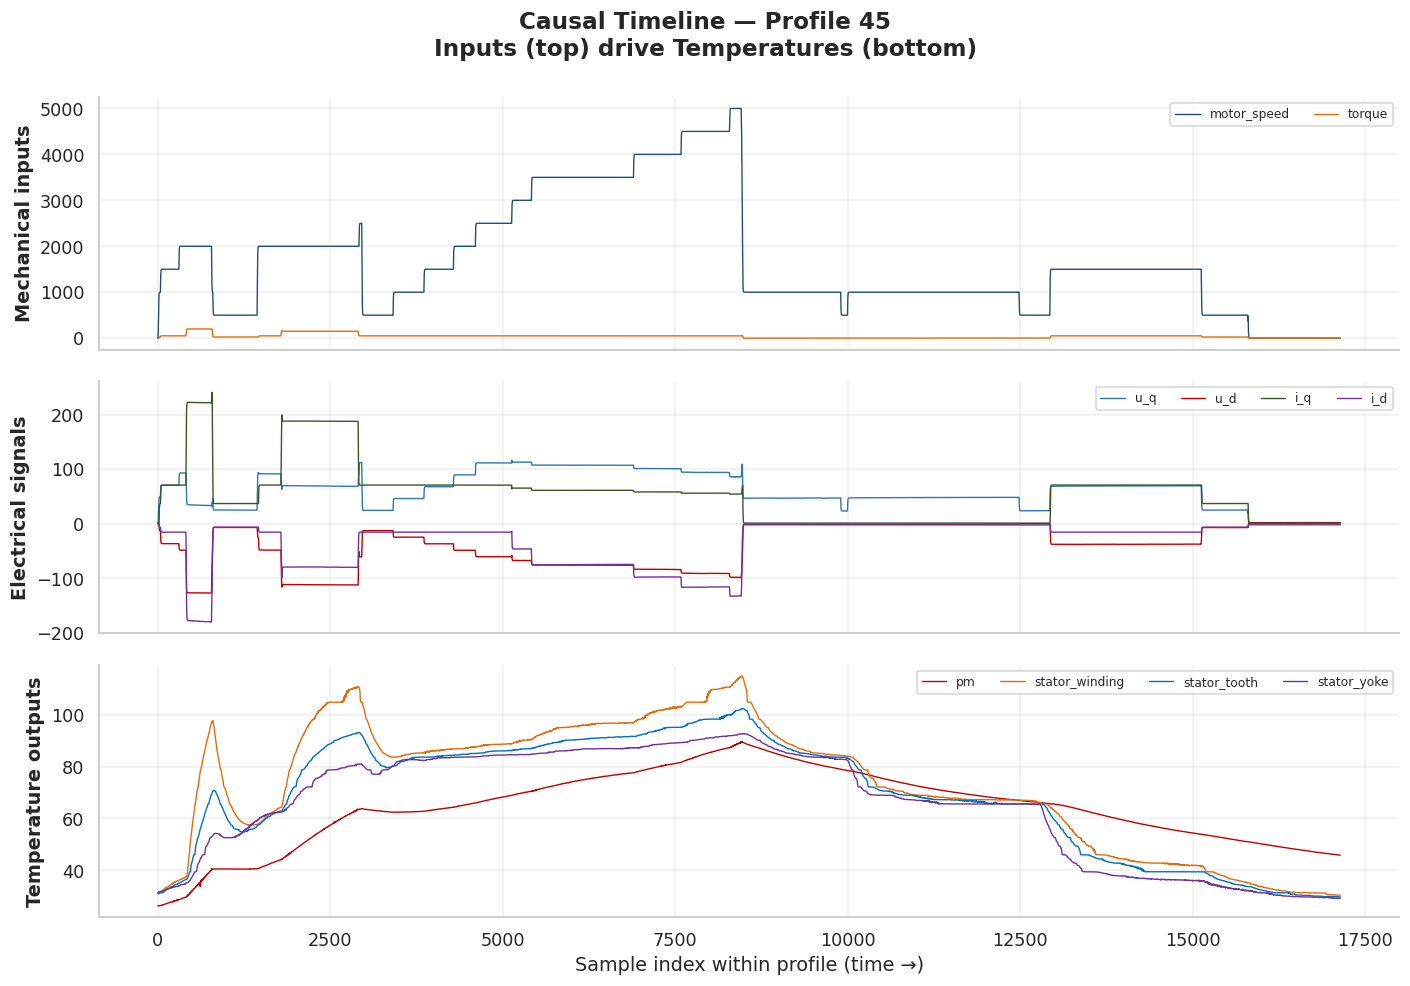

In [8]:
band_specs = [
    ("Mechanical inputs",   ["motor_speed", "torque"]),
    ("Electrical signals",  ["u_q", "u_d", "i_q", "i_d"]),
    ("Temperature outputs", ["pm", "stator_winding", "stator_tooth", "stator_yoke"]),
]

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (band, cols) in zip(axes, band_specs):
    for col in cols:
        ax.plot(prof.index, prof[col], linewidth=0.9, label=col, color=VAR_COLORS[col])
    ax.set_ylabel(band, fontweight="bold")
    ax.legend(loc="upper right", fontsize=8, ncol=len(cols)); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Sample index within profile (time \u2192)")
fig.suptitle(f"Causal Timeline — Profile {rep_profile}\nInputs (top) drive Temperatures (bottom)",
             fontweight="bold", y=0.995)
plt.tight_layout(); plt.show()

The inputs jump around sharply while the temperatures rise and fall smoothly and lag behind.
After the high-speed phase ends, the temperatures keep rising briefly and then cool down
gradually — the thermal delay is visible directly.

## 8. How the variables relate

Correlation runs from -1 to +1 and measures how strongly two variables move together (+1 rise
together, -1 move oppositely, 0 no linear link). I order the variables by category so related
ones sit together.

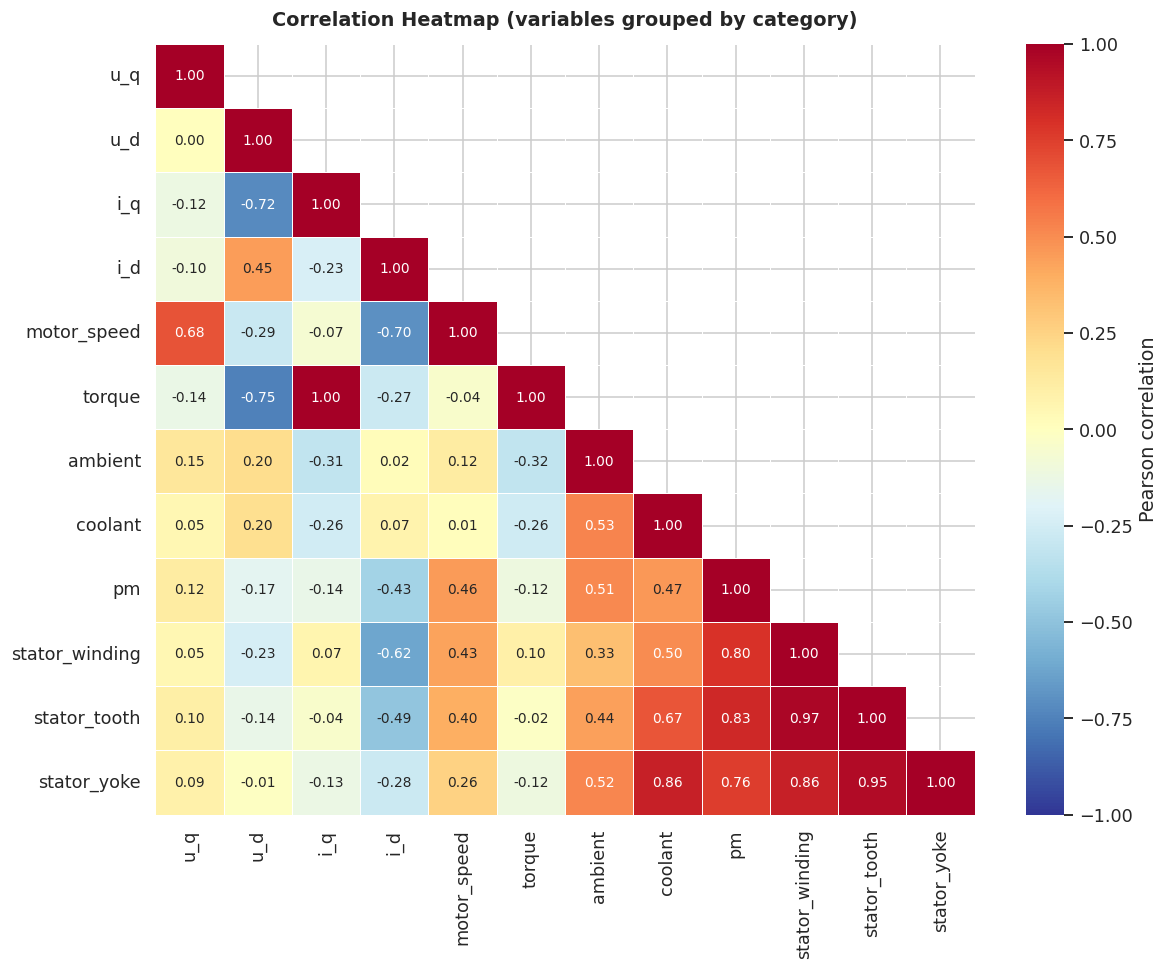

Target-target correlations:
  pm             <-> stator_winding  r = +0.796
  pm             <-> stator_tooth    r = +0.832
  pm             <-> stator_yoke     r = +0.757
  stator_winding <-> stator_tooth    r = +0.970
  stator_winding <-> stator_yoke     r = +0.860
  stator_tooth   <-> stator_yoke     r = +0.953


In [9]:
corr = df[ORDERED_VARS].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlBu_r",
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            annot_kws={"size": 9}, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation Heatmap (variables grouped by category)", fontweight="bold", pad=12)
plt.tight_layout(); plt.show()

print("Target-target correlations:")
tc = corr.loc[TARGET_FEATURES, TARGET_FEATURES]
for i, a in enumerate(TARGET_FEATURES):
    for b in TARGET_FEATURES[i+1:]:
        print(f"  {a:14s} <-> {b:14s}  r = {tc.loc[a,b]:+.3f}")

The clearest pattern is the block in the bottom-right: the four temperatures are strongly
correlated, the three stator temperatures especially (around 0.95–0.97). Among the inputs,
`ambient`, `coolant` and `motor_speed` show the clearest links to the temperatures.

One thing worth noting: because the outputs are so correlated, four targets carry less
independent information than four unrelated outputs would.

## 9. How bumpy is each variable?

A natural question is how quickly each variable changes from one timestep to the next. I measure
the average absolute step change divided by each variable's own spread, so all variables compare
fairly. The differences are computed **within** each session, so the gaps between sessions aren't
counted.

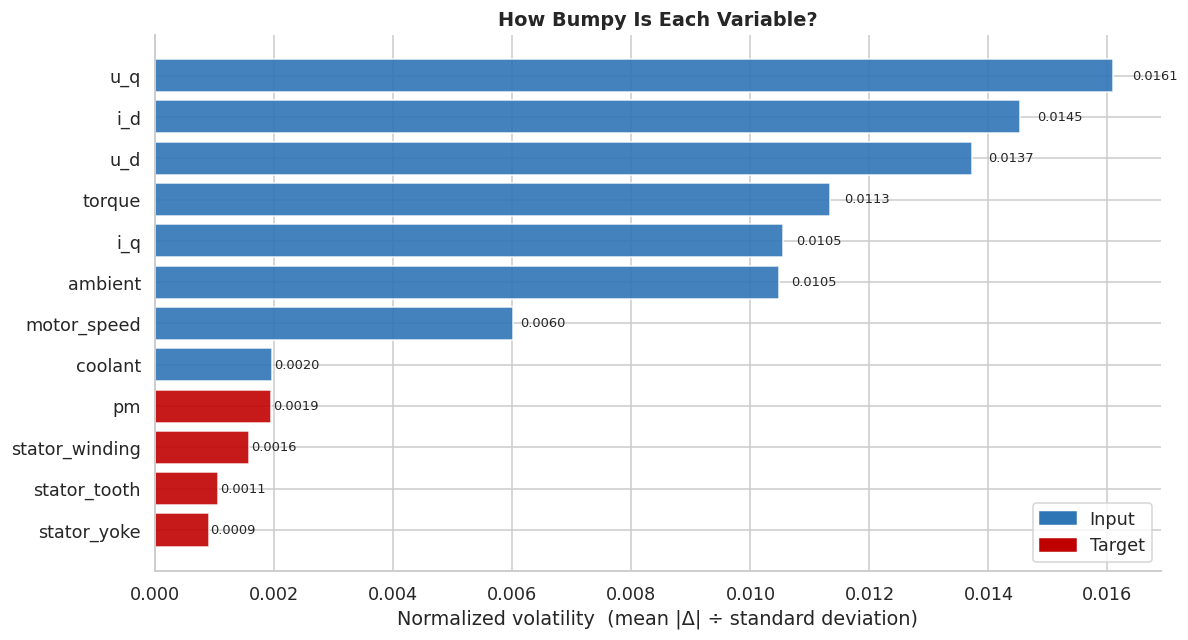

Average input volatility : 0.0106
Average target volatility: 0.0014
Inputs are about 8x more volatile than outputs.


In [10]:
diffs = df.groupby("profile_id")[ORDERED_VARS].diff()
volatility = {c: diffs[c].abs().mean() / df[c].std() for c in ORDERED_VARS}
vol = pd.Series(volatility).sort_values()

bar_colors = [C_TEMP if v in TARGET_FEATURES else C_ELEC for v in vol.index]
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(vol.index, vol.values, color=bar_colors, edgecolor="white", alpha=0.9)
for bar, val in zip(bars, vol.values):
    ax.text(val + val*0.02, bar.get_y()+bar.get_height()/2, f"{val:.4f}", va="center", fontsize=8.5)
ax.set_xlabel("Normalized volatility  (mean |Δ| ÷ standard deviation)")
ax.set_title("How Bumpy Is Each Variable?", fontweight="bold")
ax.legend(handles=[mpatches.Patch(color=C_ELEC, label="Input"),
                   mpatches.Patch(color=C_TEMP, label="Target")], loc="lower right")
plt.tight_layout(); plt.show()

inp = np.mean([volatility[c] for c in INPUT_FEATURES])
tgt = np.mean([volatility[c] for c in TARGET_FEATURES])
print(f"Average input volatility : {inp:.4f}")
print(f"Average target volatility: {tgt:.4f}")
print(f"Inputs are about {inp/tgt:.0f}x more volatile than outputs.")

The inputs (blue) sit at the top and the temperatures (red) at the bottom. On average the inputs
are roughly **8× more volatile** than the outputs. The motor behaves like a thermal filter:
fast input changes turn into slow temperature changes, because of heat capacity and thermal
inertia.

## 10. What I take from this

- The dataset is real motor data recorded across many separate sessions, and `profile_id` needs
  to be respected when splitting into train and test sets.
- The inputs change quickly while the temperatures change slowly and with a delay — this is the
  central physical behaviour of the data.
- The four temperature outputs are strongly correlated, especially the stator ones, so they
  carry less independent information than four separate outputs would suggest.
- Because the targets are smooth and well-behaved, I'd expect the data to be a reasonable fit for
  the later neural-network regression and pruning experiments — though that's what those
  experiments will actually test.